Библиотеки успешно загружены!
Обрабатывается страница 1...
Обрабатывается страница 2...
Обрабатывается страница 3...
Обрабатывается страница 4...
Обрабатывается страница 5...

Сбор данных завершён!

Первые строки таблицы:


,Цитата,Автор,Теги,Количество слов,Страница
0,“The world as we have created it is a process ...,Albert Einstein,"change, deep-thoughts, thinking, world",21,1
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling,"abilities, choices",16,1
2,“There are only two ways to live your life. On...,Albert Einstein,"inspirational, life, live, miracle, miracles",26,1
3,"“The person, be it gentleman or lady, who has ...",Jane Austen,"aliteracy, books, classic, humor",19,1
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe,"be-yourself, inspirational",16,1
5,“Try not to become a man of success. Rather be...,Albert Einstein,"adulthood, success, value",14,1
6,“It is better to be hated for what you are tha...,André Gide,"life, love",19,1
7,"“I have not failed. I've just found 10,000 way...",Thomas A. Edison,"edison, failure, inspirational, paraphrased",12,1
8,“A woman is like a tea bag; you never know how...,Eleanor Roosevelt,misattributed-eleanor-roosevelt,19,1
9,"“A day without sunshine is like, you know, nig...",Steve Martin,"humor, obvious, simile",9,1



Размер таблицы: (50, 5)

========== ОБЩАЯ СТАТИСТИКА ==========
Всего собрано цитат: 50
Количество уникальных авторов: 28
Количество уникальных тегов: 80
Средняя длина цитаты: 24.32 слов


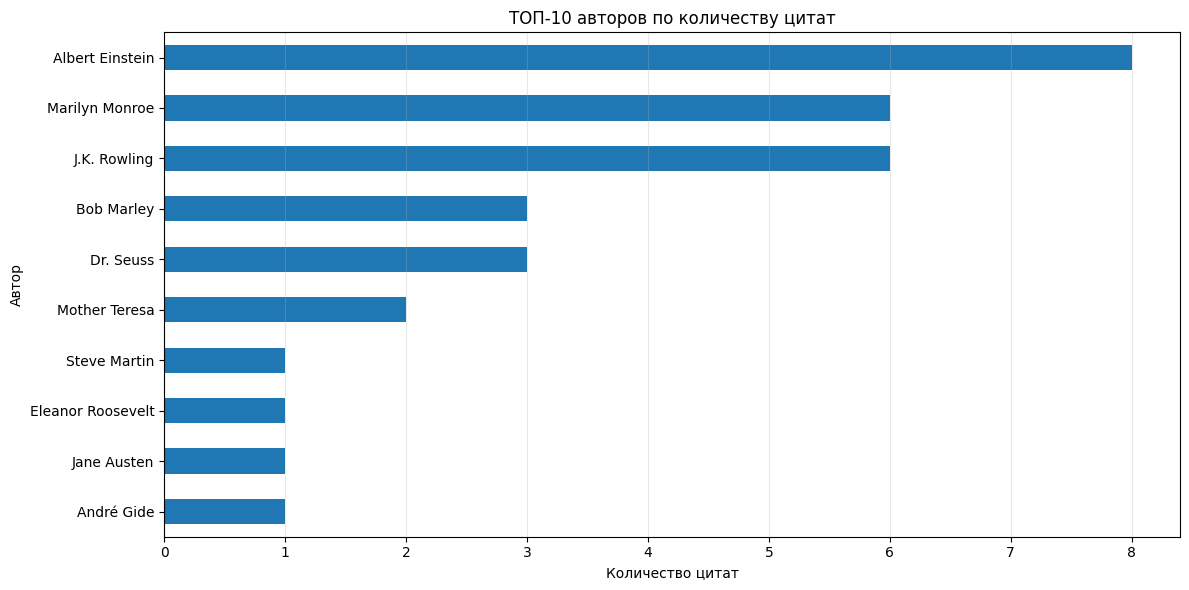

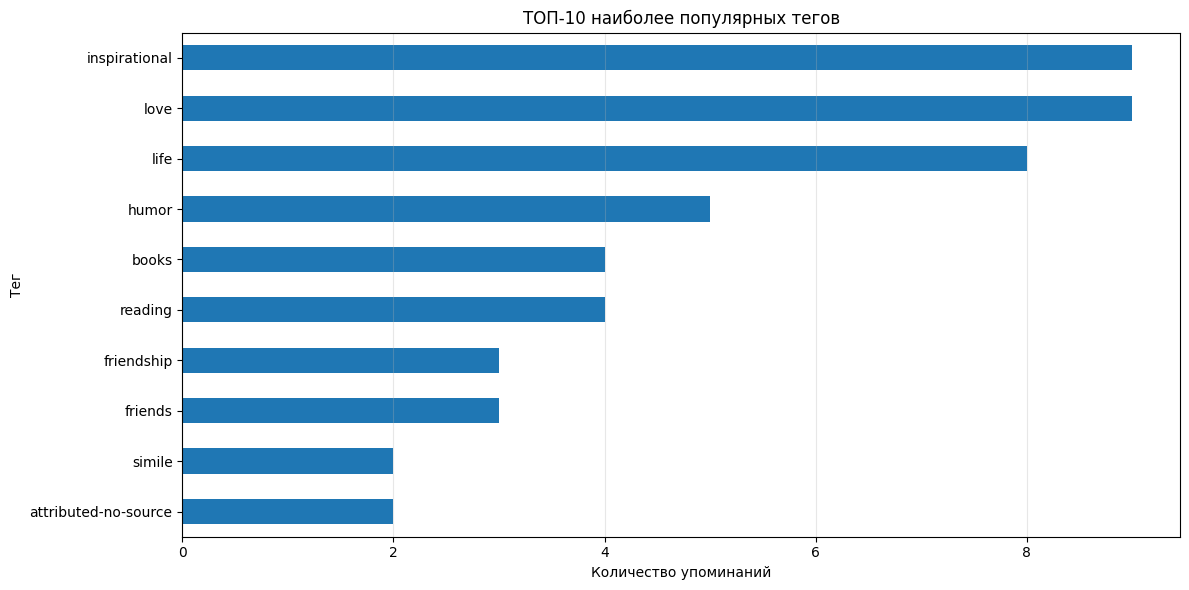

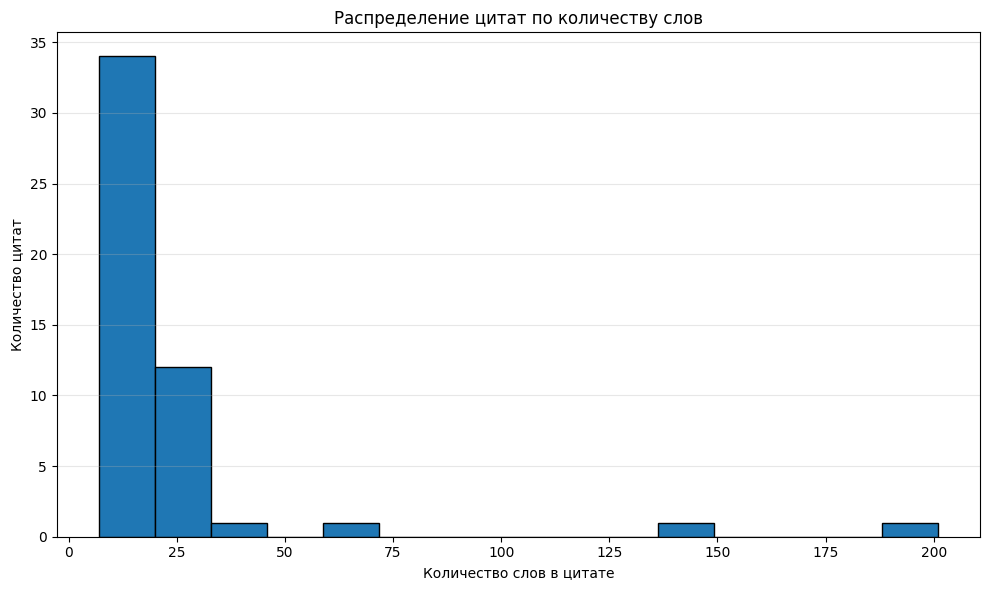

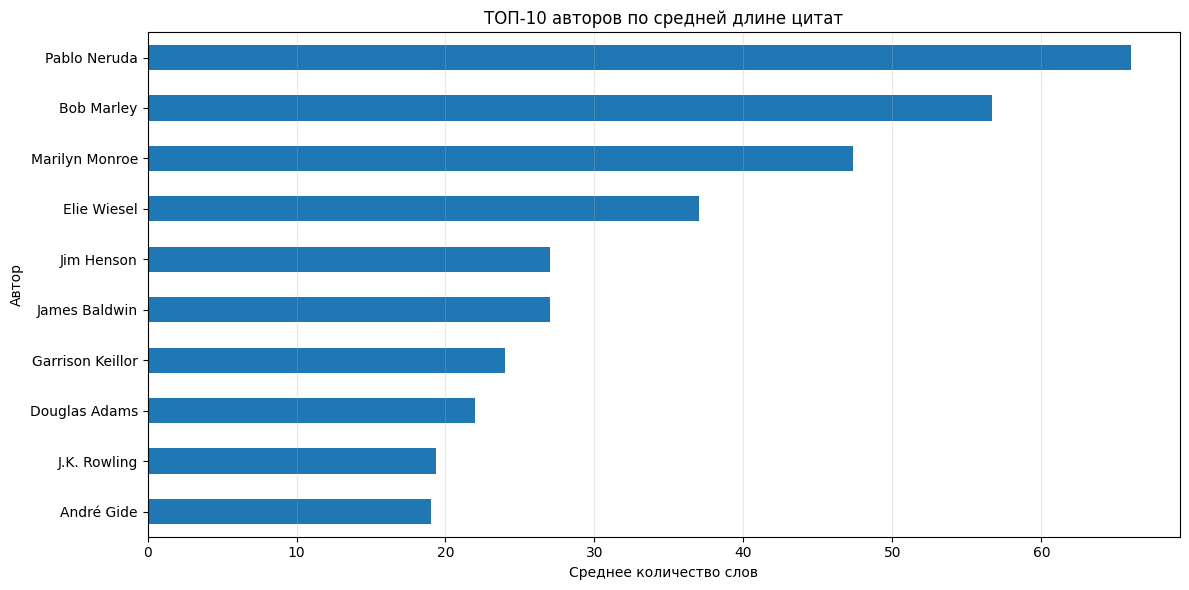


========== ДОПОЛНИТЕЛЬНЫЙ АНАЛИЗ ==========

Самые активные авторы:
Автор
Albert Einstein    8
J.K. Rowling       6
Marilyn Monroe     6
Dr. Seuss          3
Bob Marley         3
Name: count, dtype: int64

Самые популярные теги:
inspirational    9
love             9
life             8
humor            5
reading          4
dtype: int64

Самая длинная цитата:
Автор: Marilyn Monroe
Цитата: “This life is what you make it. No matter what, you're going to mess up sometimes, it's a universal truth. But the good part is you get to decide how you're going to mess it up. Girls will be your friends - they'll act like it anyway. But just remember, some come, some go. The ones that stay with you through everything - they're your true best friends. Don't let go of them. Also remember, sisters make the best friends in the world. As for lovers, well, they'll come and go too. And baby, I hate to say it, most of them - actually pretty much all of them are going to break your heart, but you can't give u

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


========== ВЫВОД ==========

В ходе работы был проведён веб-скрейпинг сайта Quotes to Scrape.

Были собраны:
- тексты цитат;
- имена авторов;
- тематические теги;
- количество слов в цитатах.

На основе собранных данных проведён анализ:
- активности авторов;
- популярности тегов;
- длины цитат;
- средней длины цитат разных авторов.

Результаты представлены в виде таблицы и графиков.
Полученные данные сохранены в CSV-файл.



In [1]:
# ============================================================
# 1. УСТАНОВКА И ИМПОРТ БИБЛИОТЕК
# ============================================================

!pip install requests beautifulsoup4 pandas matplotlib -q

import requests
import pandas as pd
import matplotlib.pyplot as plt
import time

from bs4 import BeautifulSoup
from collections import Counter
from urllib.parse import urljoin

print("Библиотеки успешно загружены!")


# ============================================================
# 2. СБОР ДАННЫХ С САЙТА
# ============================================================

base_url = "https://quotes.toscrape.com"
url = base_url

quotes_data = []

headers = {
    "User-Agent": "Mozilla/5.0"
}

# Количество страниц для сбора
pages_to_scrape = 5

for page in range(1, pages_to_scrape + 1):

    print(f"Обрабатывается страница {page}...")

    response = requests.get(
        url,
        headers=headers,
        timeout=15
    )

    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    quotes = soup.find_all("div", class_="quote")

    for quote in quotes:

        text = quote.find("span", class_="text").get_text(strip=True)

        author = quote.find(
            "small",
            class_="author"
        ).get_text(strip=True)

        tags_elements = quote.find_all("a", class_="tag")

        tags = [
            tag.get_text(strip=True)
            for tag in tags_elements
        ]

        quotes_data.append({
            "Цитата": text,
            "Автор": author,
            "Теги": ", ".join(tags),
            "Количество слов": len(text.split()),
            "Страница": page
        })

    # Переход к следующей странице
    next_page = soup.find("li", class_="next")

    if next_page and next_page.find("a"):
        next_url = next_page.find("a")["href"]
        url = urljoin(base_url, next_url)
    else:
        break

    time.sleep(1)

print("\nСбор данных завершён!")


# ============================================================
# 3. СОЗДАНИЕ И ОБРАБОТКА ТАБЛИЦЫ
# ============================================================

df = pd.DataFrame(quotes_data)

# Удаляем возможные дубликаты
df = df.drop_duplicates(subset=["Цитата"])

# Сбрасываем индексы
df = df.reset_index(drop=True)

print("\nПервые строки таблицы:")
display(df.head(10))

print("\nРазмер таблицы:", df.shape)


# ============================================================
# 4. ОБЩАЯ СТАТИСТИКА
# ============================================================

total_quotes = len(df)
unique_authors = df["Автор"].nunique()

all_tags = []

for tags in df["Теги"]:
    all_tags.extend(tags.split(", "))

unique_tags = len(set(all_tags))

average_words = df["Количество слов"].mean()

print("\n========== ОБЩАЯ СТАТИСТИКА ==========")

print("Всего собрано цитат:", total_quotes)
print("Количество уникальных авторов:", unique_authors)
print("Количество уникальных тегов:", unique_tags)
print("Средняя длина цитаты:", round(average_words, 2), "слов")


# ============================================================
# 5. ГРАФИК №1 — ТОП-10 АВТОРОВ ПО КОЛИЧЕСТВУ ЦИТАТ
# ============================================================

author_counts = df["Автор"].value_counts().head(10)

plt.figure(figsize=(12, 6))

author_counts.sort_values().plot(
    kind="barh"
)

plt.title("ТОП-10 авторов по количеству цитат")
plt.xlabel("Количество цитат")
plt.ylabel("Автор")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 6. ГРАФИК №2 — ТОП-10 ПОПУЛЯРНЫХ ТЕГОВ
# ============================================================

tag_counts = Counter(all_tags)

top_tags = pd.Series(tag_counts).sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

top_tags.sort_values().plot(
    kind="barh"
)

plt.title("ТОП-10 наиболее популярных тегов")
plt.xlabel("Количество упоминаний")
plt.ylabel("Тег")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 7. ГРАФИК №3 — РАСПРЕДЕЛЕНИЕ ДЛИНЫ ЦИТАТ
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    df["Количество слов"],
    bins=15,
    edgecolor="black"
)

plt.title("Распределение цитат по количеству слов")
plt.xlabel("Количество слов в цитате")
plt.ylabel("Количество цитат")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 8. ГРАФИК №4 — СРЕДНЯЯ ДЛИНА ЦИТАТ У АВТОРОВ
# ============================================================

author_length = (
    df.groupby("Автор")["Количество слов"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

author_length.sort_values().plot(
    kind="barh"
)

plt.title("ТОП-10 авторов по средней длине цитат")
plt.xlabel("Среднее количество слов")
plt.ylabel("Автор")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 9. ДОПОЛНИТЕЛЬНЫЙ АНАЛИЗ
# ============================================================

print("\n========== ДОПОЛНИТЕЛЬНЫЙ АНАЛИЗ ==========")

print("\nСамые активные авторы:")
print(df["Автор"].value_counts().head(5))

print("\nСамые популярные теги:")
print(top_tags.head(5))

print("\nСамая длинная цитата:")

longest_quote = df.loc[
    df["Количество слов"].idxmax()
]

print("Автор:", longest_quote["Автор"])
print("Цитата:", longest_quote["Цитата"])
print("Количество слов:", longest_quote["Количество слов"])


# ============================================================
# 10. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

df.to_csv(
    "Quotes_Analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nТаблица сохранена в файл Quotes_Analysis.csv")

from google.colab import files
files.download("Quotes_Analysis.csv")


# ============================================================
# 11. ВЫВОД
# ============================================================

print("""
========== ВЫВОД ==========

В ходе работы был проведён веб-скрейпинг сайта Quotes to Scrape.

Были собраны:
- тексты цитат;
- имена авторов;
- тематические теги;
- количество слов в цитатах.

На основе собранных данных проведён анализ:
- активности авторов;
- популярности тегов;
- длины цитат;
- средней длины цитат разных авторов.

Результаты представлены в виде таблицы и графиков.
Полученные данные сохранены в CSV-файл.
""")